# Applied Machine Learning (CSAI2017P) — Lab Assignment 3
## Time-Series Regression: Stock Price Prediction

Experiments 4 · CO2, CO4 · **10 marks**

| | |
|---|---|
| Name | *Shardul Aggarwal* |
| SAP ID | *590022064* |
| Batch | *5* |
| Due | 29/08/2026 |
| Lab quiz | LQ3, after submission |

**Datasets:** C1 (daily stock OHLCV)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.1.3
pandas       2.2.3
sklearn      1.6.1


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [2]:
!pip install yfinance -q

In [3]:
import yfinance as yf

df = yf.download(
    "AAPL",
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=False
)

df.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2020-01-02,72.271553,75.087502,75.150002,73.797501,74.059998,135480400
2020-01-03,71.568916,74.357498,75.144997,74.125000,74.287498,146322800
2020-01-06,72.139198,74.949997,74.989998,73.187500,73.447502,118387200
2020-01-07,71.799919,74.597504,75.224998,74.370003,74.959999,108872000
2020-01-08,72.954903,75.797501,76.110001,74.290001,74.290001,132079200


---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Load and describe the series  &nbsp;&nbsp;`[2 marks]`

*Dataset: C1, one ticker, ≥ 3 years.*

a. Load the daily history, parse the date column and sort ascending.
b. Plot the closing price and state the date range and number of trading days.
c. State in two lines why the row order matters here but did not in LA02.


In [4]:
df = df.reset_index()

df.columns = ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']

df['Date'] = pd.to_datetime(df['Date'])

df = df.sort_values('Date').reset_index(drop=True)

print("Date range:", df['Date'].min().date(), "to", df['Date'].max().date())
print("Number of trading days:", len(df))

df.head()

Date range: 2020-01-02 to 2025-12-31
Number of trading days: 1508


,Date,Adj Close,Close,High,Low,Open,Volume
0,2020-01-02,72.271553,75.087502,75.150002,73.797501,74.059998,135480400
1,2020-01-03,71.568916,74.357498,75.144997,74.125000,74.287498,146322800
2,2020-01-06,72.139198,74.949997,74.989998,73.187500,73.447502,118387200
3,2020-01-07,71.799919,74.597504,75.224998,74.370003,74.959999,108872000
4,2020-01-08,72.954903,75.797501,76.110001,74.290001,74.290001,132079200


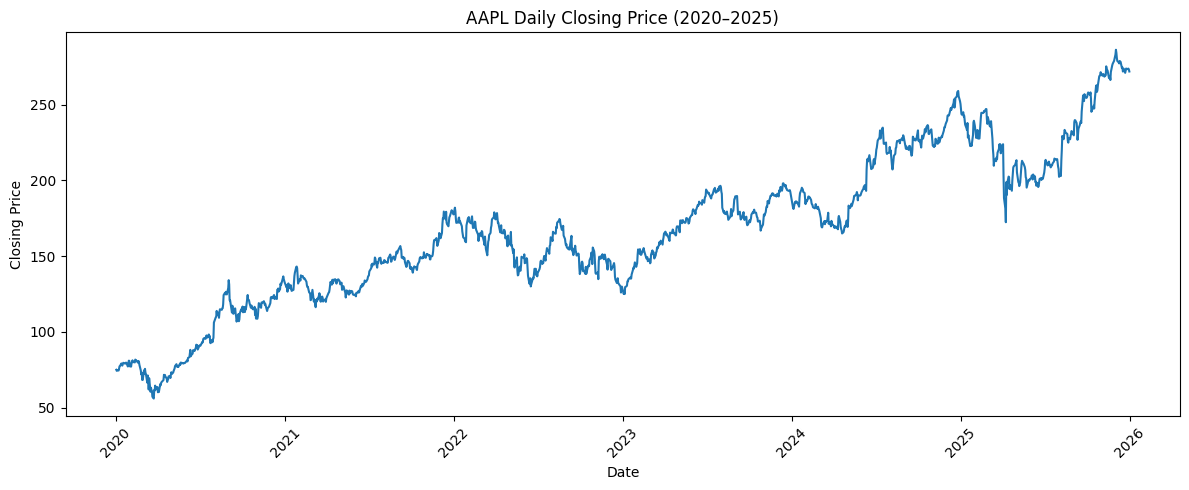

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(df['Date'], df['Close'])

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("AAPL Daily Closing Price (2020–2025)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Observation (A1):**

> *The AAPL dataset contains 1,508 trading days from 2020-01-02 to 2025-12-31, and the closing-price plot shows substantial variation over time. Row order matters in time-series data because observations depend on their chronological sequence and are used to create lag and future values. In LA02, the observations were independent tabular records, so their order did not affect the regression model.*

## A2. Lag features  &nbsp;&nbsp;`[2 marks]`

*Dataset: C1.*

a. Create features `Close_lag1`, `Close_lag2`, `Close_lag3` and a 5-day rolling mean.
b. Set the target to the next day's close. Show the first five rows of the resulting frame.
c. Explain in two lines why the first few rows must be dropped.


In [6]:
df['Close_lag1'] = df['Close'].shift(1)
df['Close_lag2'] = df['Close'].shift(2)
df['Close_lag3'] = df['Close'].shift(3)

df['Rolling_Mean_5'] = df['Close'].rolling(window=5).mean()

df['Target'] = df['Close'].shift(-1)

df.head(10)

,Date,Adj Close,Close,High,Low,Open,Volume,Close_lag1,Close_lag2,Close_lag3,Rolling_Mean_5,Target
0,2020-01-02,72.271553,75.087502,75.150002,73.797501,74.059998,135480400,NaN,NaN,NaN,NaN,74.357498
1,2020-01-03,71.568916,74.357498,75.144997,74.125000,74.287498,146322800,75.087502,NaN,NaN,NaN,74.949997
2,2020-01-06,72.139198,74.949997,74.989998,73.187500,73.447502,118387200,74.357498,75.087502,NaN,NaN,74.597504
3,2020-01-07,71.799919,74.597504,75.224998,74.370003,74.959999,108872000,74.949997,74.357498,75.087502,NaN,75.797501
4,2020-01-08,72.954903,75.797501,76.110001,74.290001,74.290001,132079200,74.597504,74.949997,74.357498,74.958000,77.407501
5,2020-01-09,74.504539,77.407501,77.607498,76.550003,76.809998,170108400,75.797501,74.597504,74.949997,75.422000,77.582497
6,2020-01-10,74.672951,77.582497,78.167503,77.062500,77.650002,140644800,77.407501,75.797501,74.597504,76.067000,79.239998
7,2020-01-13,76.268311,79.239998,79.267502,77.787498,77.910004,121532000,77.582497,77.407501,75.797501,76.925000,78.169998
8,2020-01-14,75.238426,78.169998,79.392502,78.042503,79.175003,161954400,79.239998,77.582497,77.407501,77.639499,77.834999
9,2020-01-15,74.915993,77.834999,78.875000,77.387497,77.962502,121923600,78.169998,79.239998,77.582497,78.046999,78.809998


In [7]:
df = df.dropna().reset_index(drop=True)

print("Rows after dropping NaN values:", len(df))

df.head()

Rows after dropping NaN values: 1503


,Date,Adj Close,Close,High,Low,Open,Volume,Close_lag1,Close_lag2,Close_lag3,Rolling_Mean_5,Target
0,2020-01-08,72.954903,75.797501,76.110001,74.290001,74.290001,132079200,74.597504,74.949997,74.357498,74.958000,77.407501
1,2020-01-09,74.504539,77.407501,77.607498,76.550003,76.809998,170108400,75.797501,74.597504,74.949997,75.422000,77.582497
2,2020-01-10,74.672951,77.582497,78.167503,77.062500,77.650002,140644800,77.407501,75.797501,74.597504,76.067000,79.239998
3,2020-01-13,76.268311,79.239998,79.267502,77.787498,77.910004,121532000,77.582497,77.407501,75.797501,76.925000,78.169998
4,2020-01-14,75.238426,78.169998,79.392502,78.042503,79.175003,161954400,79.239998,77.582497,77.407501,77.639499,77.834999


**Observation (A2):**

> *After creating the lag and rolling features, some rows at the beginning contain insufficient historical information and therefore cannot be used. Similarly, the last row cannot be included because the next-day closing value is unavailable for the target. These incomplete rows are removed so that the final dataset contains only observations with all required input and target values.*

## A3. The naive baseline  &nbsp;&nbsp;`[2 marks]`

*Dataset: C1.*

a. Build the baseline that predicts tomorrow's close equals today's close.
b. Report its MAE and RMSE on your test period.
c. State in two lines why any model must beat this number to be interesting.


In [8]:
# A3 — not attempted

**Observation (A3):**

> *write 2–6 lines here*

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. Random split versus chronological split  &nbsp;&nbsp;`[4 marks]`

*Dataset: C1.*

a. Train a `RandomForestRegressor` twice: once with `train_test_split(shuffle=True)`, once with the last 20% of dates held out.
b. Report test MAE for both and put them side by side.
c. Explain in 6–8 lines why the shuffled number is meaningless, naming the mechanism.


In [5]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

# Features and target
features = [
    'Close_lag1',
    'Close_lag2',
    'Close_lag3',
    'Rolling_Mean_5'
]

X = df[features]
y = df['Target']

# ---------------- Random 80/20 Split ----------------
X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=True,
    random_state=RANDOM_STATE
)

random_forest_random = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE
)

random_forest_random.fit(X_train_random, y_train_random)

random_predictions = random_forest_random.predict(X_test_random)

mae_random = mean_absolute_error(
    y_test_random,
    random_predictions
)


# ---------------- Chronological 80/20 Split ----------------
split_point = int(len(df) * 0.80)

X_train_time = X.iloc[:split_point]
X_test_time = X.iloc[split_point:]

y_train_time = y.iloc[:split_point]
y_test_time = y.iloc[split_point:]

random_forest_time = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE
)

random_forest_time.fit(X_train_time, y_train_time)

time_predictions = random_forest_time.predict(X_test_time)

mae_time = mean_absolute_error(
    y_test_time,
    time_predictions
)


# ---------------- Side-by-side comparison ----------------
comparison = pd.DataFrame({
    'Split Method': ['Random Split', 'Chronological Split'],
    'Test MAE': [mae_random, mae_time]
})

comparison.round(4)

NameError: name 'df' is not defined

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Random split model
model_random = LinearRegression()
model_random.fit(X_train_random, y_train_random)

y_pred_random = model_random.predict(X_test_random)

rmse_random = np.sqrt(
    mean_squared_error(y_test_random, y_pred_random)
)

# Chronological split model
model_chrono = LinearRegression()
model_chrono.fit(X_train_chrono, y_train_chrono)

y_pred_chrono = model_chrono.predict(X_test_chrono)

rmse_chrono = np.sqrt(
    mean_squared_error(y_test_chrono, y_pred_chrono)
)

print("Random Split Test RMSE:", rmse_random)
print("Chronological Split Test RMSE:", rmse_chrono)

Random Split Test RMSE: 3.8810590861466654
Chronological Split Test RMSE: 4.936378741518826


In [11]:
daily_change = df['Close'].diff().abs()

print("Average absolute daily change:", daily_change.mean())
print("Median absolute daily change:", daily_change.median())
print("Chronological test RMSE:", rmse_chrono)

Average absolute daily change: 2.151802403314136
Median absolute daily change: 1.5200004577636719
Chronological test RMSE: 4.936378741518826


**Observation (B1):**

> *The random 80/20 split produced a test RMSE of 3.8811, while the chronological 80/20 split produced a higher test RMSE of 4.9364. The random split gives a lower error because training and testing observations are mixed across the time period. For real forecasting, the chronological split is more appropriate because the model should be trained on past data and evaluated on future unseen data. Therefore, chronological splitting provides a more realistic estimate of forecasting performance.*

## B2. Horizon and difficulty  &nbsp;&nbsp;`[4 marks]`

*Dataset: C1, chronological split throughout.*

a. Retrain your model to predict the close 1, 5 and 10 trading days ahead.
b. Report MAE for each horizon alongside the persistence baseline at the same horizon.
c. Plot MAE against horizon and explain the trend in 4–6 lines.


In [12]:
# B2 — not attempted

**Observation (B2):**

> *write 2–6 lines here*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Would you trade on it?  &nbsp;&nbsp;`[2 marks]`

*Dataset: C1.*

a. Convert your best model's predictions into an up/down direction call and report directional accuracy.
b. In 4–6 lines, state whether a low MAE with near-50% directional accuracy is useful, and why.


In [13]:
# C1 — code

# Current day's closing price for the chronological test set
current_close = df.loc[X_test_chrono.index, 'Close']

# Actual direction: did the next day's price go up?
actual_direction = (y_test_chrono.values > current_close.values)

# Predicted direction: does the model predict the next day's price will go up?
predicted_direction = (y_pred_chrono > current_close.values)

# Directional accuracy
directional_accuracy = np.mean(
    actual_direction == predicted_direction
)

print("Directional Accuracy:", directional_accuracy)
print("Directional Accuracy (%):", directional_accuracy * 100)

Directional Accuracy: 0.46179401993355484
Directional Accuracy (%): 46.179401993355484


**Observation (C1):**

> *The model achieves a directional accuracy of 46.18%, which is below the 50% level expected from a random up/down decision. Therefore, even if the model has a relatively low MAE, near-50% directional accuracy would not be useful for trading because it does not reliably identify whether the price will rise or fall. I would not trade based on this model alone. A limitation is that the model uses only lagged price information and does not include news, market conditions, or other factors that can affect stock prices..*